# 이커머스 멀티모달 분석 보고서

비공개 H&M 표본을 DataAnalyzer로 읽고, 상품 피처·정제·통계·RFM·필수 차트·인사이트를 순서대로 검증한다. 원본 CSV·ZIP은 별도로 보관하며, 평가 노트북의 실제 행·ID·이미지와 실행 출력은 그대로 보존한다. 새 커널 실행은 `python -m utils.run_checks --with-sample`로 수행하고 출력이 포함된 보고서는 `data/processed/`에 저장한다. 평가 노트북에는 실행 출력을 그대로 저장한다.

관측은 선택 고객·기간·전체 판매 채널에 한정한다. 금액의 통화와 채널 의미를 추정하지 않으며, 그룹 이름을 실제 가입·이탈 상태로 단정하지 않는다.

## 설정

경로·기간·채널·시드·이미지 크기·배치·IQR 기준을 이 셀에서 관리한다. 표본 추출 설정과 다르면 새 표본을 준비한다. RFM 기준일은 고객 표본을 뽑기 전 추출 기록의 마지막 유효 구매일을 유지한다.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src/pipeline.py").is_file(): ROOT = ROOT.parent
if not (ROOT / "src/pipeline.py").is_file(): raise RuntimeError("저장소 루트 또는 notebooks에서 실행하세요.")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.pipeline import DataAnalyzer
from utils.reporting import pair_correlation, monthly_amount, make_figures, write_insights
from scripts.restore_hm_sample import sha256

DATA = ROOT / "data/raw/hm"
OUTPUT = ROOT / "data/processed"
SETTINGS = {"start_inclusive": "2020-06-01", "end_exclusive": "2020-09-01", "seed": 42,
            "sales_channel": None, "image_size": 32, "batch_size": 32, "iqr_threshold": 1.5}
manifest = json.loads((DATA / "sample_manifest.json").read_text(encoding="utf-8"))
for key in ("start_inclusive", "end_exclusive", "seed", "sales_channel"):
    assert manifest[key] == SETTINGS[key], f"표본 설정 불일치: {key}"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Python", sys.version.split()[0], "기준일", manifest["reference_date"])

Python 3.11.4 기준일 2020-08-31


## NB_LOAD · 유효 거래와 상품 연결

ID는 문자열로 읽어 선행 0을 보존한다. 원본 열 `t_dat`는 구매일, `price`는 원본 금액 단위다. 고객 누락→날짜 오류→금액 오류를 상호 배타적으로 집계한 뒤 기간·채널을 적용한다. 동일 값의 구매 행도 별도 구매 상품 행일 수 있어 유지한다.

상품은 ID 기준 다대일 왼쪽 조인한다. 상품 미매칭은 거래 무효 사유가 아니다. 빈 상품 키는 제외하고 중복 키는 오류로 처리한다. 행 수·거래 순서와 금액 합계를 검증한다.

In [2]:
analyzer = DataAnalyzer(DATA / "transactions_sample.csv")
analyzer.load_data(required_columns=["customer_id", "article_id", "t_dat", "price", "sales_channel_id"],
                   date_columns=["t_dat"])
assert len(analyzer.df) == manifest["transactions"]["sampled_rows"]
analyzer.validate_transactions(start=SETTINGS["start_inclusive"], end=SETTINGS["end_exclusive"],
    channel_col="sales_channel_id", channel=SETTINGS["sales_channel"])
extraction = manifest["transactions"]
assert extraction["source_rows"] == sum(extraction[name] for name in
    ["missing_customer_rows", "invalid_date_rows", "invalid_amount_rows", "out_of_scope_rows", "sample_excluded_rows", "sampled_rows"])
assert extraction["eligible_rows"] == extraction["sample_excluded_rows"] + extraction["sampled_rows"]
assert analyzer.transaction_audit["output_rows"] == extraction["sampled_rows"]
assert analyzer.df.customer_id.nunique() == manifest["sampled_customers"]
analyzer.join_products(DATA / "articles_sample.csv")
joined_column_count = analyzer.df.shape[1]
assert len(analyzer.df) >= 1000 and joined_column_count >= 8
assert analyzer.join_summary["rows_before"] == analyzer.join_summary["rows_after"]
assert np.isclose(analyzer.join_summary["amount_before"], analyzer.join_summary["amount_after"], rtol=1e-12, atol=1e-10)
display(analyzer.df.head())
analyzer.df.info()
display(analyzer.df.describe(include="all"))
display(pd.DataFrame([analyzer.transaction_audit, analyzer.join_summary]))
display(Markdown(f"유효 거래 {len(analyzer.df):,}행, 조인 후 {joined_column_count}열, 상품 일치율 {analyzer.join_summary['matched_rows']/len(analyzer.df):.1%}다. 구매 집계를 보존하면서 상품 단위 피처를 연결할 수 있다."))

,t_dat,customer_id,article_id,price,sales_channel_id,prod_name,product_type_name,source_image_available,image_sampled
0,2020-06-01,0283b438a640d92d2003c3b912fd5c754beb3c42976e17e26828c99733862373,0857272001,0.067780,1,HS Ninie broderi anglais,Dress,True,False
1,2020-06-01,0283b438a640d92d2003c3b912fd5c754beb3c42976e17e26828c99733862373,0856808007,0.050831,1,Uma,Dress,True,False
2,2020-06-01,0283b438a640d92d2003c3b912fd5c754beb3c42976e17e26828c99733862373,0857277001,0.033881,1,HS PI Penelope,Dress,True,False
3,2020-06-01,0283b438a640d92d2003c3b912fd5c754beb3c42976e17e26828c99733862373,0852365002,0.042356,1,Carnival,Dress,True,False
4,2020-06-01,0283b438a640d92d2003c3b912fd5c754beb3c42976e17e26828c99733862373,0852365002,0.042356,1,Carnival,Dress,True,False


<class 'pandas.DataFrame'>
RangeIndex: 8084 entries, 0 to 8083
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   t_dat                   8084 non-null   datetime64[us]
 1   customer_id             8084 non-null   string        
 2   article_id              8084 non-null   string        
 3   price                   8084 non-null   float64       
 4   sales_channel_id        8084 non-null   string        
 5   prod_name               8084 non-null   str           
 6   product_type_name       8084 non-null   str           
 7   source_image_available  8084 non-null   bool          
 8   image_sampled           8084 non-null   bool          
dtypes: bool(2), datetime64[us](1), float64(1), str(2), string(3)
memory usage: 458.0 KB


,t_dat,customer_id,article_id,price,sales_channel_id,prod_name,product_type_name,source_image_available,image_sampled
count,8084,8084,8084,8084.000000,8084,8084,8084,8084,8084
unique,NaN,1000,4705,NaN,2,3022,83,2,2
top,NaN,17d6270f6f81ad1f7e5a1cb7ed8edb54bc00d0d5c2cde6269c3f07228cff7a97,0160442007,NaN,2,Timeless Midrise Brief,Dress,True,False
freq,NaN,79,15,NaN,5196,67,1110,8058,7759
mean,2020-07-12 11:11:54.299851,NaN,NaN,0.025014,NaN,NaN,NaN,NaN,NaN
min,2020-06-01 00:00:00,NaN,NaN,0.000322,NaN,NaN,NaN,NaN,NaN
25%,2020-06-22 00:00:00,NaN,NaN,0.015237,NaN,NaN,NaN,NaN,NaN
50%,2020-07-08 00:00:00,NaN,NaN,0.022017,NaN,NaN,NaN,NaN,NaN
75%,2020-08-03 00:00:00,NaN,NaN,0.033881,NaN,NaN,NaN,NaN,NaN
max,2020-08-31 00:00:00,NaN,NaN,0.135576,NaN,NaN,NaN,NaN,NaN


,source_rows,missing_customer_rows,invalid_date_rows,invalid_order_rows,invalid_amount_rows,valid_before_scope,out_of_scope_rows,output_rows,amount_sum,rows_before,rows_after,amount_before,amount_after,matched_rows,unmatched_rows,excluded_empty_product_keys
0,8084.0,0.0,0.0,0.0,0.0,8084.0,0.0,8084.0,202.212746,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8084.0,8084.0,202.212746,202.212746,8084.0,0.0,0.0


유효 거래 8,084행, 조인 후 9열, 상품 일치율 100.0%다. 구매 집계를 보존하면서 상품 단위 피처를 연결할 수 있다.

## NB_FEATURES · 상품 단위 이미지·텍스트

이미지 파일은 상품별 한 번 읽고 픽셀 통계는 `(N,H,W,C)`의 `axis=(1,2,3)`에서 계산한다. 회색조는 RGB로 확장하고 RGBA는 알파를 제외한다. 정수 픽셀은 자료형 최대값으로 정규화하고 NumPy 인덱싱으로 32×32로 줄인다. 표준편차는 `ddof=0`이다. 이 피처는 축소 이미지의 밝기·색상·배경을 함께 요약하며 질감이나 구매 원인을 직접 측정하지 않는다.

상품명 결측 수를 먼저 기록한 뒤, 계산 시에만 빈 문자열로 처리한다. 상품 피처는 `analyzer.products`, 거래에 연결한 피처는 `analyzer.df`에 둔다.

,Products
not_sampled,4496
ok,200
missing,9


,prod_name_length,prod_name_word_count,image_mean,image_std
count,4705.000000,4705.000000,200.000000,200.000000
mean,16.009777,2.830393,0.780095,0.209193
std,6.071876,1.086859,0.102098,0.123963
min,2.000000,1.000000,0.486299,0.010001
25%,12.000000,2.000000,0.699966,0.100404
50%,16.000000,3.000000,0.800454,0.210652
75%,20.000000,4.000000,0.867357,0.325432
max,30.000000,7.000000,0.920713,0.397130


최대 실제 배치 {'shape': (5, 32, 32, 3), 'dtype': 'float32', 'strides': (12288, 384, 12, 4), 'nbytes': 61440, 'c_contiguous': True}


상품 4,705개 중 이미지 관측은 200개(4.3%)다. 이미지 관계 해석은 관측 상품에 한정하며 전체 상품을 대표한다고 가정하지 않는다. 원래 결측 상품명은 0개다.

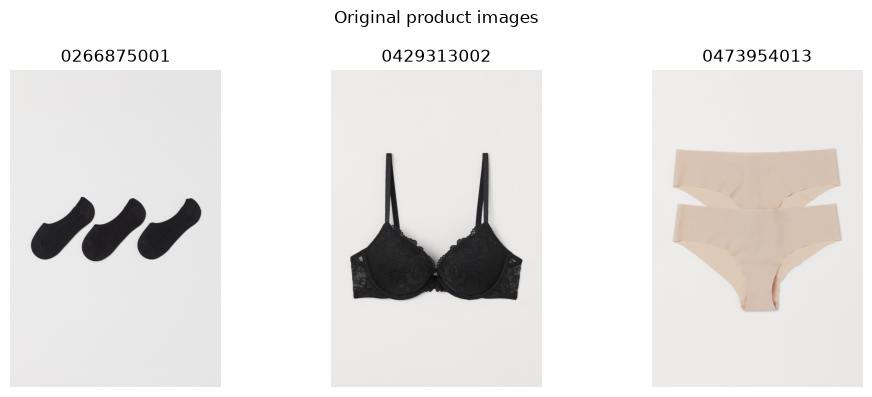

In [3]:
missing_product_names = int(analyzer.products.prod_name.isna().sum())
analyzer.extract_text_features("prod_name")
analyzer.extract_image_features(image_dir=DATA / "images", image_size=SETTINGS["image_size"], batch_size=SETTINGS["batch_size"])
products = analyzer.products.copy()
statuses = products.image_status.value_counts().to_dict()
assert statuses.get("ok", 0) == manifest["sampled_images"]
assert statuses.get("missing", 0) == manifest["matched_products_without_images"]
assert statuses.get("not_sampled", 0) == manifest["products_with_images_outside_image_sample"]
assert products.loc[products.image_status != "ok", ["image_mean", "image_std"]].isna().all().all()
display(pd.Series(statuses, name="Products").to_frame())
display(products[["prod_name_length", "prod_name_word_count", "image_mean", "image_std"]].describe())
print("최대 실제 배치", analyzer.image_batch_info)
display(Markdown(f"상품 {len(products):,}개 중 이미지 관측은 {statuses.get('ok',0):,}개({statuses.get('ok',0)/len(products):.1%})다. 이미지 관계 해석은 관측 상품에 한정하며 전체 상품을 대표한다고 가정하지 않는다. 원래 결측 상품명은 {missing_product_names}개다."))
fixture = DataAnalyzer("fixture.csv")
fixture.df = pd.DataFrame({"prod_name": ["Blue cotton shirt"], "image": [np.array([[0,0],[1,1]], dtype=np.float32)]})
fixture.extract_text_features("prod_name"); fixture.extract_image_features("image")
assert fixture.df.prod_name_length.iloc[0] == 17 and fixture.df.prod_name_word_count.iloc[0] == 3
np.testing.assert_allclose(fixture.df[["image_mean", "image_std"]].to_numpy(), .5)
# 실제 원본 상품 이미지와 상품 ID를 평가자가 확인할 수 있도록 표시한다.
from matplotlib.image import imread
examples = products.loc[products.image_status == "ok"].head(3)
image_figure, image_axes = plt.subplots(1, len(examples), figsize=(10, 4), squeeze=False)
for axis, article_id in zip(image_axes.flat, examples.article_id):
    article_id = str(article_id)
    axis.imshow(imread(DATA / "images" / article_id[:3] / (article_id + ".jpg")))
    axis.set_title(article_id)
    axis.axis("off")
image_figure.suptitle("Original product images")
image_figure.tight_layout()
display(image_figure)
plt.close(image_figure)


## NB_CLEAN · 결측과 이상치

원본 이미지 피처를 보존하고 EDA 사본만 카테고리별 평균으로 대치한다. 그룹 평균이 없으면 대치 전 전체 관측 평균을 사용한다. 표본 미포함 이미지는 대치에서 제외하며, 관측값과 원본 거래금액은 바꾸지 않는다. 대치는 피처의 분산을 줄일 수 있으므로 상관·산점도에는 원래 관측 이미지 피처를 사용한다.

IQR은 Q3−Q1이고, 기본 하한·상한은 Q1−1.5×IQR과 Q3+1.5×IQR이다. 경계값은 포함한다. EDA용 금액 사본만 보정하며 고액의 실제 구매를 오류로 확정하지 않는다.

In [4]:
imputer = DataAnalyzer("product-features.csv")
imputer.df = products.copy()
for column in ("image_mean", "image_std"): imputer.df[column + "_eda"] = products[column]
imputer.handle_missing_values(group_col="product_type_name", columns=["image_mean_eda", "image_std_eda"],
                              eligible=products.image_status != "not_sampled")
for column in ("image_mean", "image_std"):
    observed = products[column].notna()
    np.testing.assert_allclose(imputer.df.loc[observed, column + "_eda"], products.loc[observed, column])
assert imputer.df.loc[products.image_status == "not_sampled", "image_mean_eda"].isna().all()
display(pd.DataFrame(imputer.missing_audit).T)
raw_amount = analyzer.df.price.copy()
clipped_amount = analyzer.clip_outliers("price", threshold=SETTINGS["iqr_threshold"])
pd.testing.assert_series_equal(raw_amount, analyzer.df.price)
display(pd.DataFrame(analyzer.outlier_audit).T)
display(Markdown(f"IQR로 표시한 거래는 {analyzer.outlier_audit['price']['count']:,}행이다. 원래 금액 합계 {raw_amount.sum():.6f}를 RFM·월별 집계에 유지하고, 보정된 사본은 분포 비교에만 사용한다."))
# 손계산 입력: 그룹 평균 20, 전체 평균 30, 기존 관측값 50을 보존한다.
small = DataAnalyzer("fixture.csv")
small.df = pd.DataFrame({"category":["A","A","A",None,None], "x":[10,30,np.nan,50,np.nan]})
small.handle_missing_values(group_col="category", columns=["x"])
np.testing.assert_allclose(small.df.x, [10,30,20,50,30])

,missing_before,group_filled,global_filled,missing_after,variance_before,variance_after
image_mean_eda,4505.0,9.0,0.0,4496.0,0.010424,0.010130
image_std_eda,4505.0,9.0,0.0,4496.0,0.015367,0.014955


,lower,upper,count,threshold
price,-0.012729,0.061847,212.0,1.5


IQR로 표시한 거래는 212행이다. 원래 금액 합계 202.212746를 RFM·월별 집계에 유지하고, 보정된 사본은 분포 비교에만 사용한다.

## NB_RFM · 지표·점수·세그먼트

Recency는 추출 기록 기준일과 마지막 구매일의 차이이며 기준일 구매는 0일이다. H&M에는 주문 ID가 없어 Frequency를 고유 구매일 수로 정의한다. Monetary는 유효 거래금액 원값 합계다. 같은 값은 평균 순위를 사용해 같은 점수를 받는다. `(평균 순위−0.5)/고객 수`의 0.25·0.50·0.75 경계로 1~4점을 부여하고 최근일수는 내림차순, 빈도·금액은 오름차순으로 순위를 매긴다.

VIP(R·F·M≥3, 구매일≥2) → Loyal(R·F≥3, 구매일≥2) → New(R≥3, 구매일=1) → Churned(R≤2) → Potential 순으로 한 그룹을 배정한다. 최소 4개 비어 있지 않은 그룹을 검증한다. 이름은 관찰 기간의 상대적 상태이며 실제 신규 가입·이탈 여부를 확정하지 않는다.

In [5]:
rfm = analyzer.calculate_rfm("customer_id", "t_dat", "price", reference_date=manifest["reference_date"])
profile = analyzer.profile_segments(rfm)
assert rfm.customer_id.is_unique and len(rfm) == analyzer.df.customer_id.nunique()
assert rfm.Segment.nunique() >= 4
assert profile.Customers.sum() == len(rfm)
assert np.isclose(profile.Monetary_total.sum(), raw_amount.sum(), rtol=1e-12, atol=1e-10)
display(profile)
display(Markdown(f"고객 {len(rfm):,}명을 {len(profile)}개 그룹으로 구분했다. VIP의 고객 비중은 {profile.loc['VIP','Customer_share']:.1%}, 금액 비중은 {profile.loc['VIP','Monetary_share']:.1%}다. 그룹별 구매금액 기여를 확인하되 캠페인 효과나 수익성을 이 비중만으로 확정하지 않는다."))
# 날짜·집계 손계산 검증: A=0·2·60, B=1·1·5, 합계 65.
small.df = pd.DataFrame({"customer_id":["A","A","A","B"], "t_dat":["2020-01-01","2020-01-01","2020-01-03","2020-01-02"], "price":[10,20,30,5]})
expected = small.calculate_rfm("customer_id","t_dat","price",reference_date="2020-01-03").set_index("customer_id")
assert expected.loc["A", ["Recency","Frequency","Monetary"]].tolist() == [0,2,60]
assert expected.loc["B", ["Recency","Frequency","Monetary"]].tolist() == [1,1,5]
assert expected.Monetary.sum() == 65
shuffled = DataAnalyzer("shuffle.csv"); shuffled.df = analyzer.df.sample(frac=1, random_state=42)
pd.testing.assert_frame_equal(rfm, shuffled.calculate_rfm("customer_id","t_dat","price",reference_date=manifest["reference_date"]))

,Customers,Recency_median,Frequency_median,Monetary_mean,Monetary_total,Customer_share,Monetary_share
Segment,,,,,,,
VIP,270,12.5,3.0,0.391468,105.696288,0.270,0.522698
Churned,499,60.0,1.0,0.149389,74.545203,0.499,0.368647
New,149,18.0,1.0,0.101617,15.140949,0.149,0.074876
Loyal,82,16.0,2.0,0.083296,6.830305,0.082,0.033778


고객 1,000명을 4개 그룹으로 구분했다. VIP의 고객 비중은 27.0%, 금액 비중은 52.3%다. 그룹별 구매금액 기여를 확인하되 캠페인 효과나 수익성을 이 비중만으로 확정하지 않는다.

## NB_STATS · 요약 통계와 상관관계

거래 가격 통계는 거래 단위, 이미지 상관은 상품 단위, Frequency–Monetary 상관은 고객 단위다. 쌍별 완전 관측 수를 함께 표시하고 상수 열·표본 부족은 해석에서 제외한다. 상관은 인과를 의미하지 않는다. Frequency와 Monetary는 같은 구매 기록에서 만들어져 구조적으로 관련될 수 있다.

In [6]:
statistics = analyzer.summarize(["price", "prod_name_length", "prod_name_word_count"])
correlations = [pair_correlation(products.loc[products.image_status == "ok"], "image_mean", "image_std"),
                pair_correlation(rfm, "Frequency", "Monetary")]
assert all(item["n"] >= 2 and np.isfinite(item["pearson"]) for item in correlations)
display(statistics); display(pd.DataFrame(correlations))
display(Markdown(f"거래금액 평균은 {statistics.loc['price','mean']:.6f}, 중앙값은 {statistics.loc['price','median']:.6f}, 표준편차는 {statistics.loc['price','std']:.6f} 원본 단위다. 평균·중앙값과 꼬리를 함께 확인하고 평균만으로 전형적인 구매를 대표하지 않는다."))
for pair in correlations:
    display(Markdown(f"{pair['left']}–{pair['right']}: 유효 쌍 {pair['n']:,}개, Pearson r={pair['pearson']:.3f}. 이 계수는 해당 분석 단위의 선형 연관 요약이며, 인과·캠페인 효과를 설명하지 않는다."))
image_pair, customer_pair = correlations
display(Markdown(f"관측 이미지의 r={image_pair['pearson']:.3f}은 평균이 높은 이미지에서 픽셀 퍼짐이 낮아지는 경향을 보인다. 밝은 배경 등 촬영 조건의 영향을 고려하며 상품 질감의 차이로 단정하지 않는다."))
display(Markdown(f"고객의 빈도–금액 r={customer_pair['pearson']:.3f}은 반복 구매일이 많은 고객의 관측 구매금액도 큰 경향을 보인다. 두 값이 같은 거래에서 집계된다는 구조와 고객별 구매일당 금액 차이를 함께 확인해야 한다."))


,count,mean,std,min,Q1,median,Q3,max
price,8084.0,0.025014,0.014912,0.000322,0.015237,0.022017,0.033881,0.135576
prod_name_length,8084.0,16.088570,6.207140,2.000000,11.000000,16.000000,21.000000,30.000000
prod_name_word_count,8084.0,2.840673,1.105405,1.000000,2.000000,3.000000,4.000000,7.000000


,left,right,n,pearson
0,image_mean,image_std,200,-0.943546
1,Frequency,Monetary,1000,0.639664


거래금액 평균은 0.025014, 중앙값은 0.022017, 표준편차는 0.014912 원본 단위다. 평균·중앙값과 꼬리를 함께 확인하고 평균만으로 전형적인 구매를 대표하지 않는다.

image_mean–image_std: 유효 쌍 200개, Pearson r=-0.944. 이 계수는 해당 분석 단위의 선형 연관 요약이며, 인과·캠페인 효과를 설명하지 않는다.

Frequency–Monetary: 유효 쌍 1,000개, Pearson r=0.640. 이 계수는 해당 분석 단위의 선형 연관 요약이며, 인과·캠페인 효과를 설명하지 않는다.

관측 이미지의 r=-0.944은 평균이 높은 이미지에서 픽셀 퍼짐이 낮아지는 경향을 보인다. 밝은 배경 등 촬영 조건의 영향을 고려하며 상품 질감의 차이로 단정하지 않는다.

고객의 빈도–금액 r=0.640은 반복 구매일이 많은 고객의 관측 구매금액도 큰 경향을 보인다. 두 값이 같은 거래에서 집계된다는 구조와 고객별 구매일당 금액 차이를 함께 확인해야 한다.

## NB_PLOTS · 필수 차트 6종

히스토그램·전후 박스플롯은 거래, 막대·히트맵은 고객, 산점도는 관측 상품, 라인차트는 완전한 월 단위다. 박스플롯은 같은 축의 원값·EDA 사본을 비교한다. 모든 차트에 제목·축·단위를 표시한다. 가격의 왜도, 빈도·금액의 구조적 연관과 이미지 표본의 낮은 포함률을 함께 고려한다.

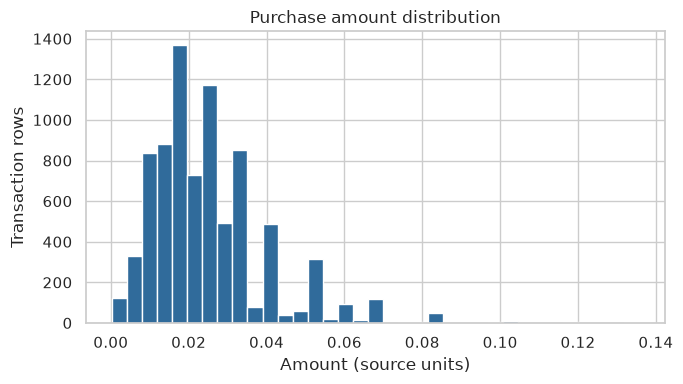

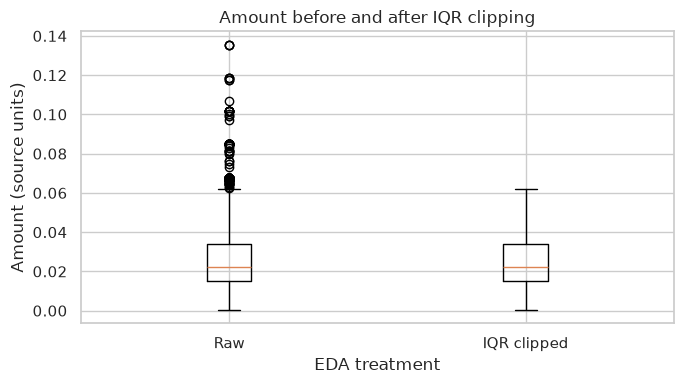

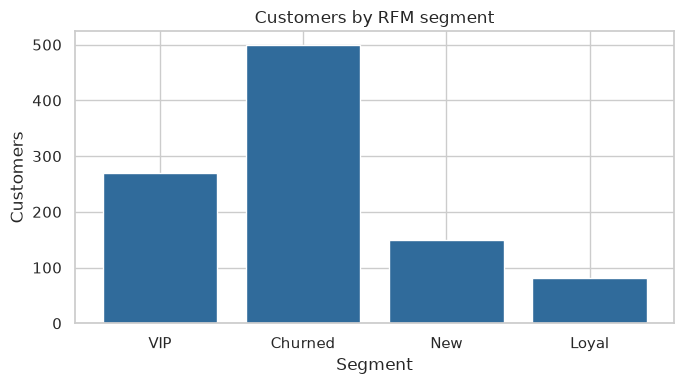

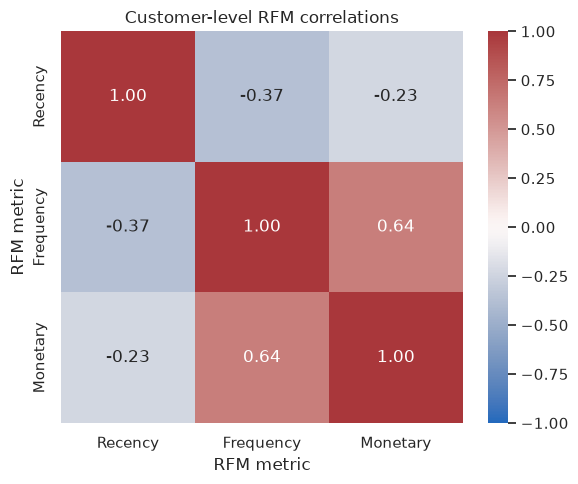

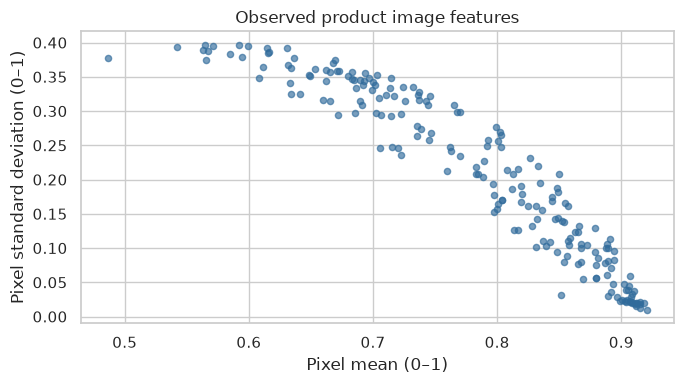

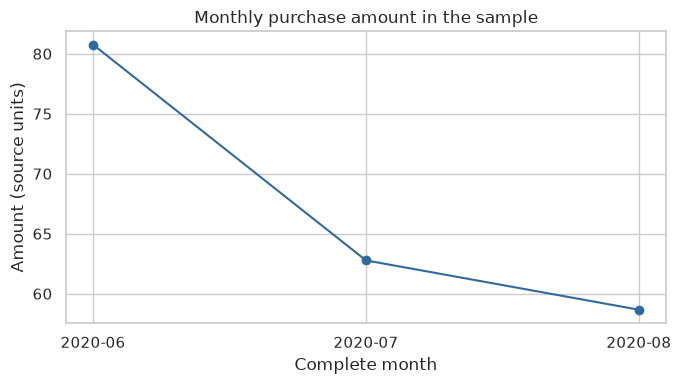

,Amount
2020-06,80.766000
2020-07,62.779373
2020-08,58.667373


관찰한 완전한 월은 3개이고 월별 금액 합계 202.212746가 RFM 입력 금액과 같다. 이 추세는 선택 고객의 관측 기간 안에서 해석하며 전체 시장 매출로 일반화하지 않는다.

첫 달 대비 마지막 달의 표본 금액 변화는 -27.4%다. 전체 고객이 아닌 선택 고객의 세 달 관측이며, 이후 캠페인이나 예측에 사용하려면 계절성과 고객 선택 편향을 추가로 확인해야 한다.

In [7]:
monthly = monthly_amount(analyzer.df, "t_dat", "price", SETTINGS["start_inclusive"], SETTINGS["end_exclusive"])
figures = make_figures(analyzer.df, clipped_amount, products, rfm, profile, monthly)
assert len(figures) == 6 and all(fig.axes[0].get_title() and fig.axes[0].get_xlabel() and fig.axes[0].get_ylabel() for fig in figures.values())
figure_dir = OUTPUT / "figures"; figure_dir.mkdir(exist_ok=True)
for name, fig in figures.items():
    fig.savefig(figure_dir / (name + ".png"), dpi=120, bbox_inches="tight")
    display(fig); plt.close(fig)
display(monthly.to_frame())
display(Markdown(f"관찰한 완전한 월은 {len(monthly)}개이고 월별 금액 합계 {monthly.sum():.6f}가 RFM 입력 금액과 같다. 이 추세는 선택 고객의 관측 기간 안에서 해석하며 전체 시장 매출로 일반화하지 않는다."))
change = monthly.iloc[-1] / monthly.iloc[0] - 1 if monthly.iloc[0] else float("nan")
display(Markdown(f"첫 달 대비 마지막 달의 표본 금액 변화는 {change:.1%}다. 전체 고객이 아닌 선택 고객의 세 달 관측이며, 이후 캠페인이나 예측에 사용하려면 계절성과 고객 선택 편향을 추가로 확인해야 한다."))


## 실제 결과의 비즈니스 해석

근거는 고객 집계 표에서 선택하고 실행 효과는 검증할 가설로 구분한다. 추가로 필요한 연락 동의·비용·마진·향후 반응 데이터를 명시한다.

In [8]:
insights = write_insights(profile, manifest["reference_date"], OUTPUT / "insights.md")
display(Markdown(insights))

# 실제 표본 기반 인사이트

기준일 2020-08-31. 2020년 6~8월의 선택 고객·전체 판매 채널 표본에 한정한 관측이다. 금액은 H&M 원본 단위이며 통화를 추정하지 않는다. 아래 비중은 고객별 RFM에서 집계했고 원본 행·식별자는 포함하지 않는다. 표 위치는 노트북 `NB_RFM`의 세그먼트 프로파일이다.

## 1. VIP 유지 실험

- **근거:** VIP는 고객의 27.0%이며 관측 구매금액의 52.3%를 차지한다. 고액·반복 구매 그룹의 유지 성과를 따로 관찰할 이유가 있다.
- **실행:** VIP에 재입고·신상품 우선 알림을 시험하고, 불필요한 상시 할인 없이 재구매를 유지할 수 있는지 확인한다. 효과는 가설이다.
- **검증:** 발송군과 무작위 미발송군의 이후 구매율·고객당 마진을 비교한다. 반응 이력·마진·추가 관찰 기간이 필요하며 차이가 없으면 가설을 기각한다.

## 2. 최근 1개 구매일 고객의 다음 구매 유도

- **근거:** New 그룹은 고객의 14.9%이고 고유 구매일 수 중앙값은 1일이다. 관찰 기간 내 한 구매일만 확인된 그룹이며 실제 신규 가입 고객을 뜻하지 않는다.
- **실행:** 이 그룹에 구매 상품군을 고려한 후속 안내를 시험해 두 번째 구매일이 생기는 비율을 높이는 것을 목표로 한다.
- **검증:** 미발송군 대비 30일 내 추가 구매일 발생률과 마진을 비교한다. 연락 동의·상품 반응·향후 거래가 필요하며 자연 재구매와 계절성의 영향을 통제한다.

## 3. 낮은 최근성 그룹의 재활성화 타당성 확인

- **근거:** Churned는 고객의 49.9%이고 최근 구매 이후 일수 중앙값은 60일이다. 표본 내 상대적으로 낮은 최근성 그룹이며 실제 이탈 확정값은 아니다.
- **실행:** 이 그룹의 과거 반복 구매 여부를 나눠 재입고 안내나 제한된 혜택을 소규모로 실험한다. 재활성화 효과와 비용을 함께 확인한다.
- **검증:** 무작위 대조군과 순증 구매율·혜택 비용 차감 후 마진을 비교한다. 비용·상품 재고·후속 거래가 필요하며 수익이 늘지 않으면 확대하지 않는다.

세 인사이트의 우선순위와 ROI는 현재 데이터만으로 확정하지 않는다. 이미지 평균·표준편차는 밝기·배경·색상 요약이며 상품 패턴이나 구매 원인을 직접 설명하지 않는다.


## NB_REPRO · 재현 기록

설정·입력 체크섬·거래/고객/상품 수·기준일·조인·월별 합계·그룹별 고객/금액을 JSON으로 저장한다. 새 복제본의 새 커널 결과와 대조한다. 이 저장본에는 원본 거래 행·고객 ID·상품 이미지가 없다. 평가 노트북은 실제 실행 출력을 그대로 보존한다.

In [9]:
summary = {"settings": SETTINGS, "reference_date": manifest["reference_date"],
    "input_sha256": {name: sha256(DATA / name) for name in ["transactions_sample.csv", "articles_sample.csv", "sample_manifest.json"]},
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__},
    "transaction_rows": len(analyzer.df), "customers": len(rfm), "products": len(products),
    "joined_columns": joined_column_count, "feature_columns": list(analyzer.df.columns),
    "cleaning": analyzer.transaction_audit, "extraction": extraction, "join": analyzer.join_summary,
    "image_statuses": statuses, "largest_batch": analyzer.image_batch_info,
    "imputation": imputer.missing_audit, "outliers": analyzer.outlier_audit,
    "rfm": analyzer.rfm_audit, "profile": profile.to_dict(orient="index"),
    "correlations": correlations, "monthly": monthly.to_dict(), "figures": list(figures)}
def json_scalar(value):
    if isinstance(value, np.generic): return value.item()
    raise TypeError(type(value).__name__)
(OUTPUT / "analysis_verification.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=json_scalar, allow_nan=False), encoding="utf-8")
profile.to_csv(OUTPUT / "segment_profile.csv")
print("전체 분석·검증 완료. 결과를 data/processed에 저장했습니다.")

전체 분석·검증 완료. 결과를 data/processed에 저장했습니다.
